# Reyhana Abdikher Somo
# AnalystLab Africa — Week 1, Track B (Data Science)
# Airbnb Pricing, Location and Listing Characteristics Investigation

Primary research problem. How does advertised listing price vary with room type, capacity, bedrooms and neighbourhood within each city (local currency), and how do review activity and listing-level ratings relate to one another?

 

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':150, 'savefig.bbox':'tight'})

DATA_DIR = Path(os.environ.get('DATA_DIR', 'data'))
OUT = Path(os.environ.get('OUT_DIR', 'outputs')); FIG = OUT/'figures'; TAB = OUT/'tables'
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)

SEED, MIN_N, ALPHA = 42, 30, 0.05      # MIN_N = minimum group size admitted to a test
np.random.seed(SEED)

# The Listings table has NO currency field. The data dictionary says prices are "in each country's currency".
# The mapping below is an ASSUMPTION inferred from the city (checked for plausibility against median prices).
CURRENCY = {'Paris':'EUR','Rome':'EUR','New York':'USD','Sydney':'AUD','Rio de Janeiro':'BRL','Istanbul':'TRY',
            'Mexico City':'MXN','Bangkok':'THB','Cape Town':'ZAR','Hong Kong':'HKD'}
RESULTS = {}                            # key numbers collected for the report

def savefig(name):
    plt.savefig(FIG/name); plt.show()
def fmt_p(p):
    return '<1e-300' if p < 1e-300 else (f'{p:.2e}' if p < 1e-3 else f'{p:.4f}')

In [2]:
L = pd.read_csv(DATA_DIR/'Listings.csv', encoding='utf-8', encoding_errors='replace', low_memory=False)
dd_l = pd.read_csv(DATA_DIR/'Listings_data_dictionary.csv'); dd_r = pd.read_csv(DATA_DIR/'Reviews_data_dictionary.csv')

con = duckdb.connect()
try: con.execute("SET enable_progress_bar=false")
except Exception: pass
con.execute(f"""CREATE VIEW reviews AS SELECT * FROM read_csv('{(DATA_DIR/'Reviews.csv').as_posix()}', header=true,
    types={{'listing_id':'BIGINT','review_id':'BIGINT','date':'DATE','reviewer_id':'BIGINT'}})""")
con.register('listings_min', L[['listing_id','city','host_id']])

print('Listings:', L.shape, '| Reviews rows:', con.execute('SELECT count(*) FROM reviews').fetchall()[0][0])
display(dd_l.merge(pd.DataFrame({'Field':L.columns,'pandas dtype':L.dtypes.astype(str).values}), on='Field'))
display(dd_r)

Listings: (279712, 33) | Reviews rows: 5373143


,Field,Description,pandas dtype
0,listing_id,Listing ID,int64
1,name,Listing Name,str
2,host_id,Host ID,int64
3,host_since,Date the Host joined Airbnb,str
4,host_location,Location where the Host is based,str
5,host_response_time,Estimate of how long the Host takes to respond,str
6,host_response_rate,Percentage of times the Host responds,float64
7,host_acceptance_rate,Percentage of times the Host accepts a booking...,float64
8,host_is_superhost,Binary field to determine if the Host is a Sup...,str
9,host_total_listings_count,Total listings the Host has in Airbnb,float64


,Field,Description
0,listing_id,Listing ID
1,review_id,Review ID
2,date,Review date
3,reviewer_id,Reviewer ID


In [3]:
dq = {}
dq['listings_rows'], dq['listings_cols'] = L.shape
dq['listing_id_unique'] = bool(L.listing_id.is_unique); dq['listing_id_nulls'] = int(L.listing_id.isna().sum())
dq['listings_full_row_duplicates'] = int(L.duplicated().sum())

q = lambda s: con.execute(s).fetchall()[0]
dq['reviews_rows'], dq['reviews_distinct_review_id'], dq['reviews_distinct_listing_ids'], dq['reviews_distinct_pairs'], dq['date_min'], dq['date_max'], dq['reviews_null_cells'] = q('''
    SELECT count(*), count(DISTINCT review_id), count(DISTINCT listing_id), count(DISTINCT (listing_id, review_id)),
           min(date), max(date), count(*)*4 - (count(listing_id)+count(review_id)+count(date)+count(reviewer_id)) FROM reviews''')
dq['date_min'], dq['date_max'] = str(dq['date_min'])[:10], str(dq['date_max'])[:10]
dq['duplicated_review_ids'] = dq['reviews_rows'] - dq['reviews_distinct_review_id']
dq['orphan_reviews'] = q('SELECT count(*) FROM reviews r LEFT JOIN listings_min l USING(listing_id) WHERE l.listing_id IS NULL')[0]
dq['listings_with_reviews'] = dq['reviews_distinct_listing_ids']
dq['listings_without_reviews'] = dq['listings_rows'] - dq['listings_with_reviews']

# encoding
txt = ['name','host_location','neighbourhood','city','property_type']
dq['replacement_char_cells'] = {c:int(L[c].astype(str).str.contains('\ufffd').sum()) for c in txt}
dq['mojibake_name_cells'] = int(L.name.astype(str).str.contains('Ã|Â').sum())
for k,v in dq.items(): print(f'{k:35s} {v}')

listings_rows                       279712
listings_cols                       33
listing_id_unique                   True
listing_id_nulls                    0
listings_full_row_duplicates        0
reviews_rows                        5373143
reviews_distinct_review_id          5372983
reviews_distinct_listing_ids        193556
reviews_distinct_pairs              5373143
date_min                            2008-11-16
date_max                            2021-03-01
reviews_null_cells                  0
duplicated_review_ids               160
orphan_reviews                      0
listings_with_reviews               193556
listings_without_reviews            86156
replacement_char_cells              {'name': 5, 'host_location': 2, 'neighbourhood': 977, 'city': 0, 'property_type': 0}
mojibake_name_cells                 21702


In [4]:
dups = con.sql('''
  WITH d AS (SELECT * FROM reviews WHERE review_id IN (SELECT review_id FROM reviews GROUP BY 1 HAVING count(*)>1))
  SELECT d.review_id, count(*) n_rows, count(DISTINCT d.listing_id) n_listings, count(DISTINCT d.reviewer_id) n_reviewers,
         count(DISTINCT d.date) n_dates, count(DISTINCT l.host_id) n_hosts, count(DISTINCT l.city) n_cities
  FROM d JOIN listings_min l USING(listing_id) GROUP BY 1''').df()
dup_summary = pd.Series({
    'duplicated review_ids': len(dups),
    'rows involved': int(dups.n_rows.sum()),
    'each id appears exactly twice': bool((dups.n_rows==2).all()),
    'always 2 different listings': bool((dups.n_listings==2).all()),
    'always the same reviewer': bool((dups.n_reviewers==1).all()),
    'always the same date': bool((dups.n_dates==1).all()),
    'always 2 different hosts': bool((dups.n_hosts==2).all()),
    'always the same city': bool((dups.n_cities==1).all()),
    'share of all review rows': f"{dups.n_rows.sum()/dq['reviews_rows']:.5%}"})
display(dup_summary.to_frame('value'))
dq['dup_summary'] = {k:(v if not isinstance(v,(np.bool_,np.integer)) else v.item()) for k,v in dup_summary.items()}
display(con.sql('''SELECT r.review_id, r.listing_id, l.city, r.date, r.reviewer_id FROM reviews r JOIN listings_min l USING(listing_id)
   WHERE review_id IN (SELECT review_id FROM reviews GROUP BY 1 HAVING count(*)>1) ORDER BY review_id, listing_id LIMIT 6''').df())

,value
duplicated review_ids,160
rows involved,320
each id appears exactly twice,True
always 2 different listings,True
always the same reviewer,True
always the same date,True
always 2 different hosts,True
always the same city,True
share of all review rows,0.00596%


,review_id,listing_id,city,date,reviewer_id
0,200088015,2997346,Rome,2017-10-04,123346683
1,200088015,22219088,Rome,2017-10-04,123346683
2,205182329,2997346,Rome,2017-10-21,23770481
3,205182329,22219088,Rome,2017-10-21,23770481
4,223954194,2997346,Rome,2018-01-02,77129337
5,223954194,22219088,Rome,2018-01-02,77129337


,missing,pct
district,242700,86.77
host_response_time,128782,46.04
host_response_rate,128782,46.04
host_acceptance_rate,113087,40.43
review_scores_value,91785,32.81
review_scores_location,91775,32.81
review_scores_checkin,91771,32.81
review_scores_accuracy,91713,32.79
review_scores_communication,91687,32.78
review_scores_cleanliness,91665,32.77


,district,host_response_time,host_response_rate,host_acceptance_rate,bedrooms,review_scores_rating,review_scores_value,host_location
city,,,,,,,,
Bangkok,100.0,45.5,45.5,42.9,11.1,42.2,42.3,0.3
Cape Town,100.0,26.4,26.4,26.0,7.2,29.6,29.8,0.5
Hong Kong,100.0,16.2,16.2,23.7,17.4,46.7,46.7,0.3
Istanbul,100.0,35.5,35.5,41.0,8.3,54.2,54.3,0.3
Mexico City,100.0,28.0,28.0,24.5,4.0,27.8,28.0,0.4
New York,0.0,50.0,50.0,39.5,9.7,27.7,27.8,0.3
Paris,100.0,63.9,63.9,50.7,20.7,25.7,25.8,0.3
Rio de Janeiro,100.0,30.1,30.1,35.8,6.6,39.4,39.5,0.4
Rome,100.0,41.2,41.2,29.3,3.2,24.4,24.7,0.2


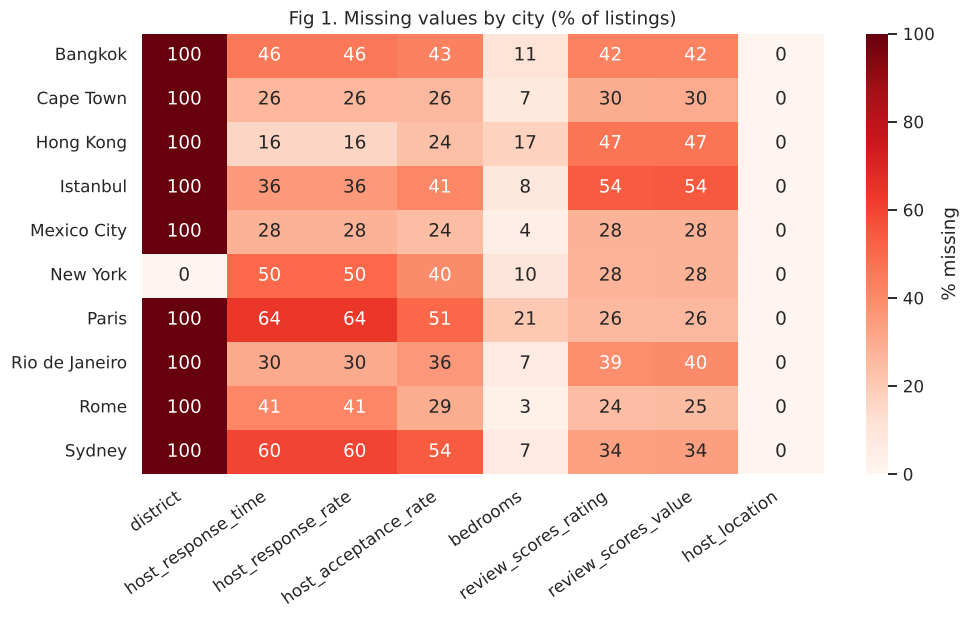

has rating,False,True
has review rows,,
False,86155,1
True,5250,188306


host_response_time and host_response_rate missing together: True
bedrooms: min = 1.0 (no listing has 0 bedrooms -> a missing value may mean studio, but this is NOT verifiable)
accommodates == 0 : 85 listings


In [5]:
miss = pd.DataFrame({'missing': L.isna().sum(), 'pct': (L.isna().mean()*100).round(2)})
miss = miss[miss.missing>0].sort_values('missing', ascending=False); display(miss)
miss.to_csv(TAB/'dq_missing_values.csv')
dq['missing'] = miss.to_dict('index')

cols = ['district','host_response_time','host_response_rate','host_acceptance_rate','bedrooms','review_scores_rating','review_scores_value','host_location']
miss_city = L.groupby('city')[cols].apply(lambda g: g.isna().mean()*100).round(1)
display(miss_city); miss_city.to_csv(TAB/'dq_missing_by_city.csv')

fig, ax = plt.subplots(figsize=(10,5.2))
sns.heatmap(miss_city, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar_kws={'label':'% missing'}, ax=ax)
ax.set_title('Fig 1. Missing values by city (% of listings)'); ax.set_ylabel(''); plt.xticks(rotation=35, ha='right')
savefig('fig01_missingness_by_city.png')

# Is a missing rating just "no reviews"?
rc = con.sql('SELECT listing_id, count(*) AS review_count, min(date) AS first_review, max(date) AS last_review FROM reviews GROUP BY 1').df()
L = L.merge(rc, on='listing_id', how='left'); L['review_count'] = L.review_count.fillna(0).astype(int)
ct = pd.crosstab(L.review_count>0, L.review_scores_rating.notna(), rownames=['has review rows'], colnames=['has rating']); display(ct)
dq['crosstab_reviews_vs_rating'] = {'no_reviews_no_rating':int(ct.loc[False,False]), 'no_reviews_rating':int(ct.loc[False,True]),
                                    'reviews_no_rating':int(ct.loc[True,False]), 'reviews_rating':int(ct.loc[True,True])}
print('host_response_time and host_response_rate missing together:', bool((L.host_response_time.isna()==L.host_response_rate.isna()).all()))
print('bedrooms: min =', L.bedrooms.min(), '(no listing has 0 bedrooms -> a missing value may mean studio, but this is NOT verifiable)')
print('accommodates == 0 :', int((L.accommodates==0).sum()), 'listings')

In [6]:
dq['price_dtype'] = str(L.price.dtype); dq['price_nonpositive'] = int((L.price<=0).sum())
display(L.loc[L.price<=0,'city'].value_counts().rename('non-positive prices').to_frame().T)

A = L[L.price>0].copy()                                  # analysis table; raw L is preserved
A['currency'] = A.city.map(CURRENCY); A['log_price'] = np.log10(A.price)
A.loc[A.accommodates==0,'accommodates'] = np.nan         # 0 guests is not a valid capacity
def _fence(g):                                           # extreme = outside Q1-3*IQR / Q3+3*IQR of log10(price) within city
    q1,q3 = g.quantile([.25,.75]); i = q3-q1; return (g<q1-3*i)|(g>q3+3*i)
A['price_extreme'] = A.groupby('city').log_price.transform(_fence).astype(bool)
dq['analysis_rows'] = len(A); dq['extreme_flagged'] = int(A.price_extreme.sum())

def pct(s,p): return s.quantile(p)
price_tab = A.groupby('city').agg(currency=('currency','first'), n=('price','size'), mean=('price','mean'), median=('price','median'),
    p25=('price',lambda s:pct(s,.25)), p75=('price',lambda s:pct(s,.75)), p5=('price',lambda s:pct(s,.05)), p95=('price',lambda s:pct(s,.95)),
    max=('price','max'), extreme_flagged=('price_extreme','sum')).sort_values('n', ascending=False)
price_tab['extreme_%'] = (price_tab.extreme_flagged/price_tab.n*100).round(2)
display(price_tab.round(1)); price_tab.to_csv(TAB/'price_summary_by_city_local_currency.csv')
print('rows kept for analysis:', len(A), '| extreme prices flagged (kept, used in sensitivity checks):', dq['extreme_flagged'])

city,Paris,New York,Mexico City,Rio de Janeiro,Rome,Istanbul,Bangkok
non-positive prices,62,28,7,7,6,2,1


,currency,n,mean,median,p25,p75,p5,p95,max,extreme_flagged,extreme_%
city,,,,,,,,,,,
Paris,EUR,64628,113.2,80.0,59.0,120.0,35.0,270.0,12000,192,0.3
New York,USD,36984,143.0,99.0,60.0,151.0,35.0,349.0,10000,62,0.2
Sydney,AUD,33630,222.0,120.0,74.0,219.0,40.0,700.0,28613,28,0.1
Rome,EUR,27641,105.1,65.0,45.0,99.0,25.0,240.0,10571,104,0.4
Rio de Janeiro,BRL,26608,742.8,280.0,157.0,550.0,78.0,1957.0,625216,51,0.2
Istanbul,TRY,24517,532.6,252.0,150.0,449.0,79.0,1185.0,179532,53,0.2
Mexico City,MXN,20058,1149.7,664.0,392.0,1124.0,225.0,2861.1,499000,37,0.2
Bangkok,THB,19360,2078.4,1100.0,700.0,1900.0,400.0,5286.7,300177,80,0.4
Cape Town,ZAR,19086,2405.1,1069.0,650.0,2200.0,350.0,7867.5,180000,22,0.1


rows kept for analysis: 279599 | extreme prices flagged (kept, used in sensitivity checks): 641


In [7]:
print('Listings with >=1 review row :', int((L.review_count>0).sum()), f"({(L.review_count>0).mean():.1%})")
print('Listings with no review rows :', int((L.review_count==0).sum()))
print('All review listing_ids exist in Listings:', dq['orphan_reviews']==0)
print('Cardinality: one listing -> many reviews; max reviews on one listing =', int(L.review_count.max()))

Listings with >=1 review row : 193556 (69.2%)
Listings with no review rows : 86156
All review listing_ids exist in Listings: True
Cardinality: one listing -> many reviews; max reviews on one listing = 891


,listings,share_%
city,,
Paris,64690,23.1
New York,37012,13.2
Sydney,33630,12.0
Rome,27647,9.9
Rio de Janeiro,26615,9.5
Istanbul,24519,8.8
Mexico City,20065,7.2
Bangkok,19361,6.9
Cape Town,19086,6.8


room_type,Entire place,Hotel room,Private room,Shared room
city,,,,
Paris,85.6,2.2,11.6,0.7
New York,52.4,0.8,44.9,1.9
Sydney,60.5,0.7,37.0,1.8
Rome,62.4,4.6,32.3,0.7
Rio de Janeiro,72.5,0.4,24.9,2.3
Istanbul,50.7,3.3,43.3,2.8
Mexico City,52.6,1.2,44.3,1.9
Bangkok,54.9,5.3,36.1,3.7
Cape Town,74.1,1.6,23.6,0.7


distinct property types: 144


,listings,share
property_type,,
Entire apartment,138989,49.7
Private room in apartment,47322,16.9
Private room in house,13292,4.8
Entire house,13273,4.7
Entire condominium,11250,4.0
Room in boutique hotel,5771,2.1
Entire loft,4587,1.6
Private room in condominium,4462,1.6
Private room in bed and breakfast,4238,1.5


Top-10 property types cover 88.4% of listings


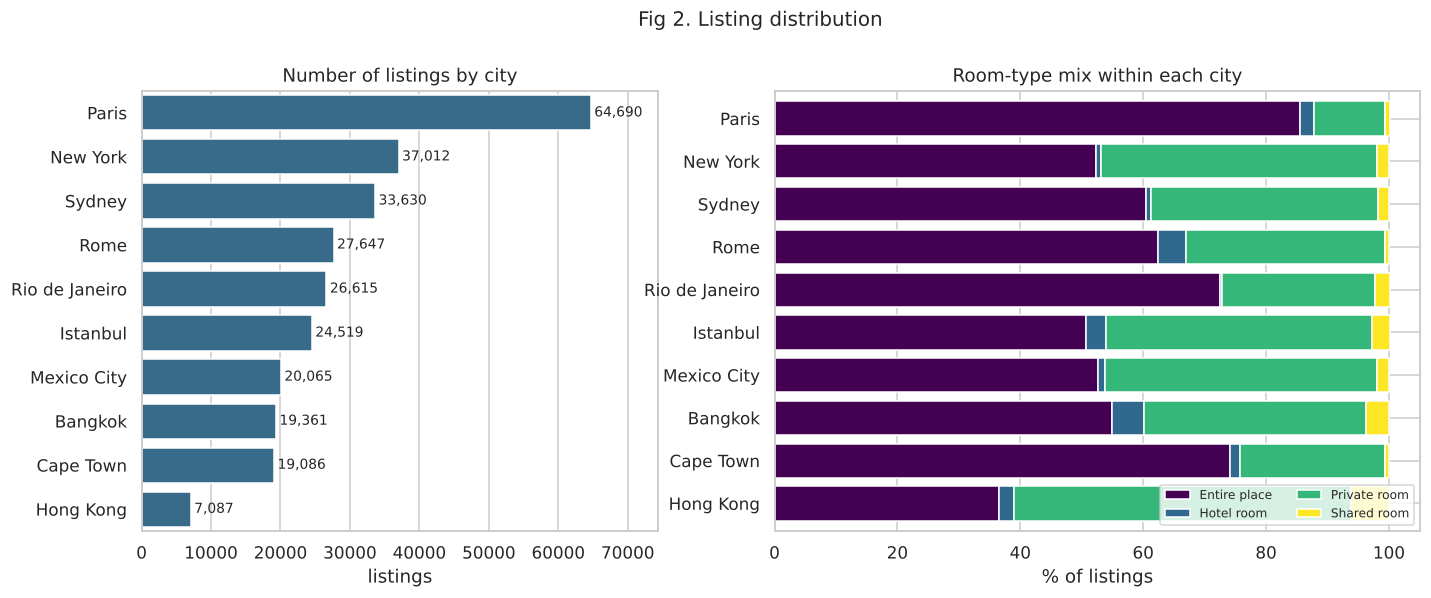

In [8]:
city_n = L.city.value_counts().rename('listings').to_frame(); city_n['share_%'] = (city_n.listings/len(L)*100).round(1)
display(city_n); city_n.to_csv(TAB/'listings_by_city.csv')
rt = pd.crosstab(L.city, L.room_type, normalize='index').mul(100).round(1); rt = rt.loc[city_n.index]; display(rt); rt.to_csv(TAB/'room_type_share_by_city.csv')
pt = L.property_type.value_counts(); print('distinct property types:', len(pt)); display(pt.head(10).to_frame('listings').assign(share=lambda d:(d.listings/len(L)*100).round(1)))
pt.to_frame('listings').to_csv(TAB/'property_type_counts.csv')
print('Top-10 property types cover', f'{pt.head(10).sum()/len(L):.1%}', 'of listings')

fig, axes = plt.subplots(1,2, figsize=(15,5.2), gridspec_kw={'width_ratios':[1,1.25]})
sns.barplot(x=city_n.listings, y=city_n.index, color='#2a6f97', ax=axes[0])
for i,v in enumerate(city_n.listings): axes[0].text(v+500, i, f'{v:,}', va='center', fontsize=9)
axes[0].set_title('Number of listings by city'); axes[0].set_xlabel('listings'); axes[0].set_ylabel(''); axes[0].set_xlim(0, city_n.listings.max()*1.15)
rt.plot(kind='barh', stacked=True, ax=axes[1], colormap='viridis', width=.8); axes[1].invert_yaxis()
axes[1].set_title('Room-type mix within each city'); axes[1].set_xlabel('% of listings'); axes[1].set_ylabel(''); axes[1].legend(title='', ncol=2, loc='lower right', fontsize=8)
plt.suptitle('Fig 2. Listing distribution', y=1.02, fontsize=13); savefig('fig02_listings_and_room_types.png')

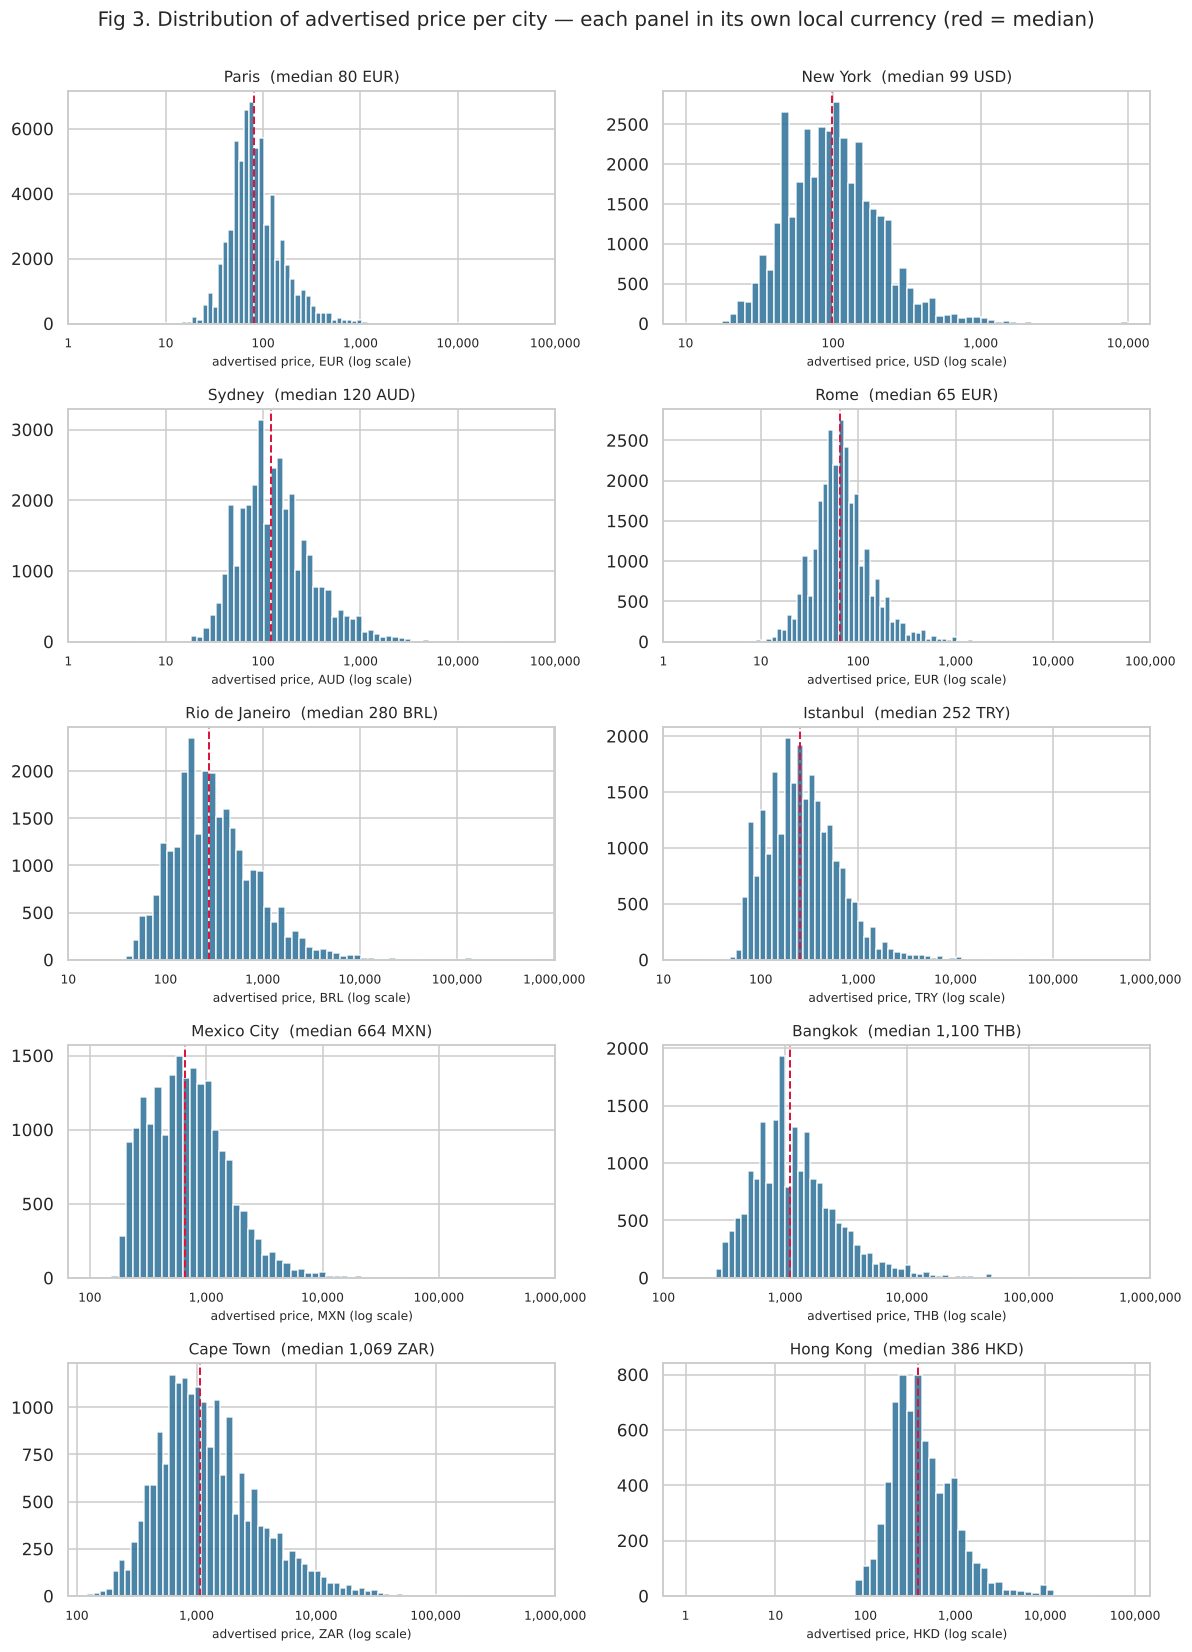

,skew_price,skew_log10_price,shapiro_p_price(n<=5000),shapiro_p_log10_price
city,,,,
Paris,29.0833,0.9686,0.0,0.0
New York,21.2881,0.7205,0.0,0.0
Sydney,20.7437,0.7642,0.0,0.0
Rome,22.6005,1.1369,0.0,0.0
Rio de Janeiro,68.2912,0.9160,0.0,0.0
Istanbul,37.9986,1.0043,0.0,0.0
Mexico City,60.7182,0.9185,0.0,0.0
Bangkok,24.8516,1.1534,0.0,0.0
Cape Town,14.3838,0.8483,0.0,0.0


In [9]:
order = list(city_n.index)
fig, axes = plt.subplots(5,2, figsize=(11,15))
for ax, c in zip(axes.ravel(), order):
    g = A[A.city==c]; ax.hist(g.log_price, bins=60, color='#2a6f97', alpha=.85)
    lo, hi = int(np.floor(g.log_price.min())), int(np.ceil(g.log_price.max()))
    ticks = [10**k for k in range(lo, hi+1)]; ax.set_xticks(np.log10(ticks)); ax.set_xticklabels([f'{t:,}' for t in ticks], fontsize=8)
    ax.axvline(np.log10(g.price.median()), color='crimson', ls='--', lw=1.3)
    ax.set_title(f'{c}  (median {g.price.median():,.0f} {CURRENCY[c]})', fontsize=10); ax.set_xlabel(f'advertised price, {CURRENCY[c]} (log scale)', fontsize=8); ax.set_ylabel('')
plt.suptitle('Fig 3. Distribution of advertised price per city — each panel in its own local currency (red = median)', y=1.0, fontsize=13)
plt.tight_layout(); savefig('fig03_price_distribution_by_city.png')

# Normality / variance assumption evidence (justifies non-parametric tests)
rng = np.random.default_rng(SEED); rows = []
for c in order:
    g = A[A.city==c]; s = g.sample(min(5000,len(g)), random_state=SEED)
    rows.append({'city':c, 'skew_price':stats.skew(g.price), 'skew_log10_price':stats.skew(g.log_price),
                 'shapiro_p_price(n<=5000)':stats.shapiro(s.price)[1], 'shapiro_p_log10_price':stats.shapiro(s.log_price)[1]})
norm_tab = pd.DataFrame(rows).set_index('city'); display(norm_tab.round(4)); norm_tab.to_csv(TAB/'assumption_normality_by_city.csv')

room_type,Entire place,Hotel room,Private room,Shared room
city,,,,
Paris,1.0,1.98,0.65,0.41
New York,1.0,1.16,0.43,0.32
Sydney,1.0,0.85,0.39,0.22
Rome,1.0,0.78,0.64,0.26
Rio de Janeiro,1.0,0.55,0.46,0.29
Istanbul,1.0,0.93,0.47,0.29
Mexico City,1.0,1.37,0.42,0.32
Bangkok,1.0,1.07,0.84,0.38
Cape Town,1.0,1.05,0.48,0.22


room_type,Entire place,Hotel room,Private room,Shared room,currency
city,,,,,
Paris,82.0,162.0,53.0,34.0,EUR
New York,140.0,163.0,60.0,45.0,USD
Sydney,176.0,149.0,68.0,39.0,AUD
Rome,77.0,60.0,49.0,20.0,EUR
Rio de Janeiro,350.0,194.0,160.0,100.0,BRL
Istanbul,350.0,325.0,163.0,100.0,TRY
Mexico City,950.0,1301.0,400.0,300.0,MXN
Bangkok,1192.0,1275.0,1000.0,450.0,THB
Cape Town,1288.0,1350.0,622.0,282.0,ZAR


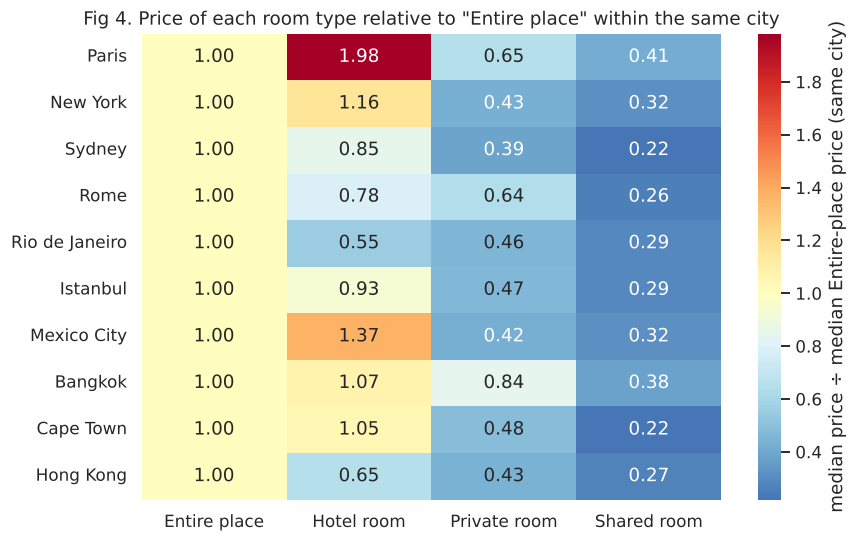

In [10]:
med = A.groupby(['city','room_type']).price.agg(['median','size']).reset_index()
base = med[med.room_type=='Entire place'].set_index('city')['median']
med['ratio_to_entire_place'] = med.apply(lambda r: r['median']/base[r.city], axis=1)
rel = med.pivot(index='city', columns='room_type', values='ratio_to_entire_place').loc[order]
cnt = med.pivot(index='city', columns='room_type', values='size').loc[order]
rel_masked = rel.where(cnt>=MIN_N)
display(rel_masked.round(2)); rel_masked.to_csv(TAB/'room_type_price_ratio_to_entire_place.csv')
display(med.pivot(index='city', columns='room_type', values='median').loc[order].round(0).assign(currency=lambda d:d.index.map(CURRENCY)))

fig, ax = plt.subplots(figsize=(8.5,5.5))
sns.heatmap(rel_masked, annot=True, fmt='.2f', cmap='RdYlBu_r', center=1, cbar_kws={'label':'median price ÷ median Entire-place price (same city)'}, ax=ax)
ax.set_title('Fig 4. Price of each room type relative to "Entire place" within the same city'); ax.set_xlabel(''); ax.set_ylabel('')
savefig('fig04_room_type_price_ratio.png')

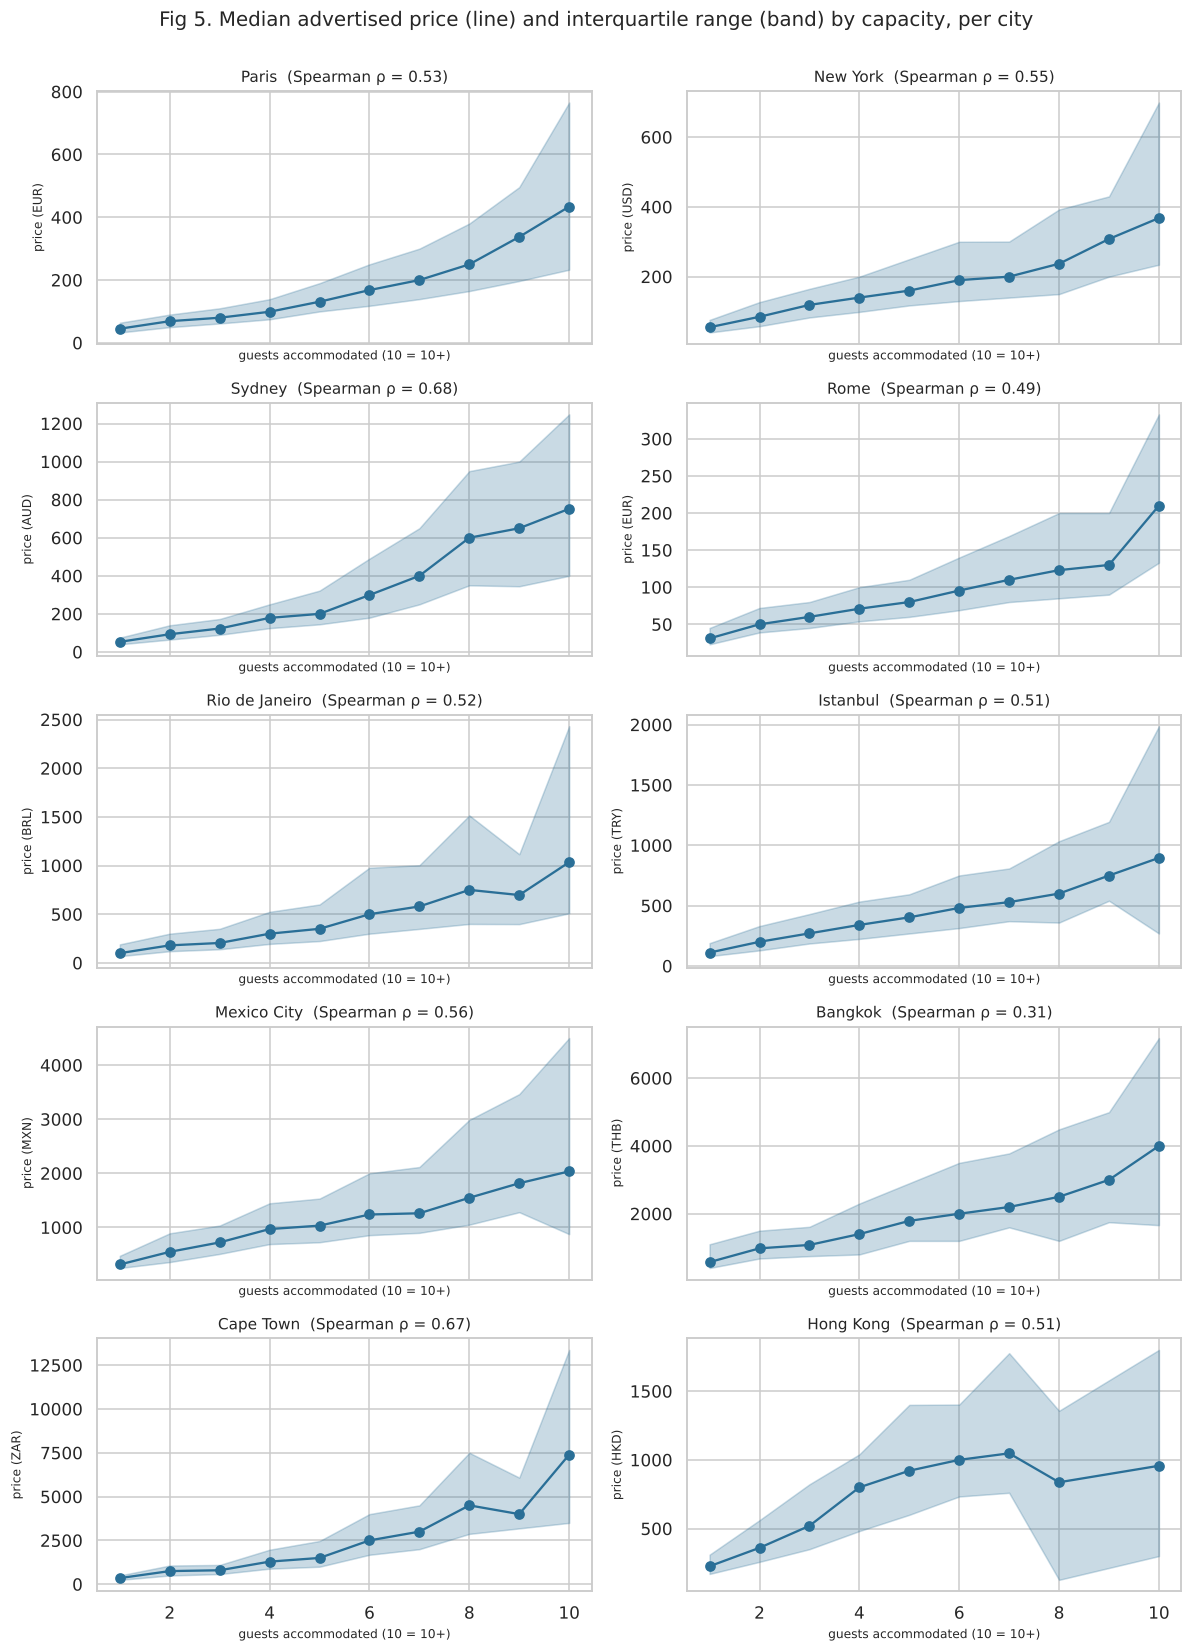

In [11]:
fig, axes = plt.subplots(5,2, figsize=(11,15), sharex=True)
for ax, c in zip(axes.ravel(), order):
    g = A[(A.city==c)&A.accommodates.notna()].copy(); g['acc'] = g.accommodates.clip(upper=10)
    s = g.groupby('acc').price.agg(med='median', q1=lambda x:x.quantile(.25), q3=lambda x:x.quantile(.75), n='size'); s = s[s.n>=MIN_N]
    ax.fill_between(s.index, s.q1, s.q3, alpha=.25, color='#2a6f97'); ax.plot(s.index, s.med, marker='o', color='#2a6f97')
    rho = stats.spearmanr(g.accommodates, g.price)[0]; ax.set_title(f'{c}  (Spearman ρ = {rho:.2f})', fontsize=10)
    ax.set_xlabel('guests accommodated (10 = 10+)', fontsize=8); ax.set_ylabel(f'price ({CURRENCY[c]})', fontsize=8)
plt.suptitle('Fig 5. Median advertised price (line) and interquartile range (band) by capacity, per city', y=1.0, fontsize=13)
plt.tight_layout(); savefig('fig05_price_vs_capacity.png')

listings with >=1 review row AND a rating: 188306
{'count': 188306.0, 'mean': 93.41, 'std': 10.07, 'min': 20.0, '25%': 91.0, '50%': 96.0, '75%': 100.0, 'max': 100.0}
share of listings with rating == 100: 30.5% | share >= 90: 81.7%


,n,mean,median,p10,share_100
rc_bin,,,,,
1,26841,90.71,100.0,60.0,73.15
2,17875,91.99,100.0,80.0,60.36
3-5,30889,92.95,96.0,80.0,45.25
6-10,26018,93.70,96.0,84.0,26.59
11-25,33476,94.41,96.0,87.0,12.62
26-50,22218,94.64,96.0,89.0,4.81
51-100,17281,94.84,96.0,89.0,3.67
100+,13708,94.72,96.0,90.0,1.53


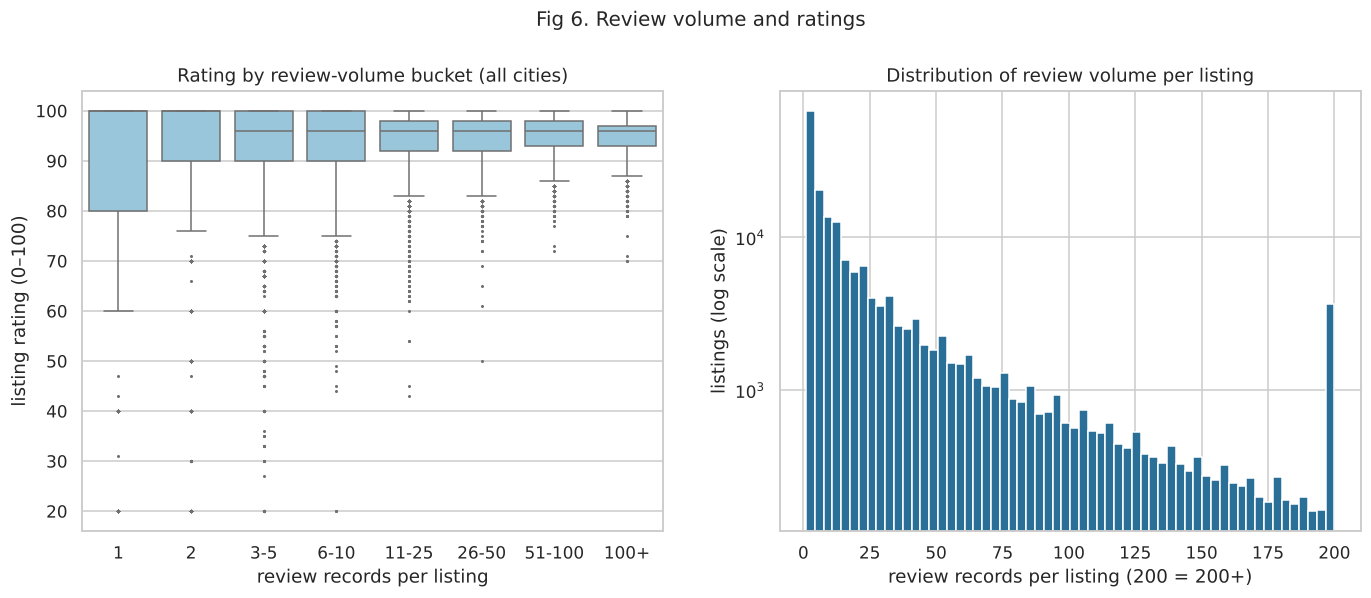

Top 10 listings by number of review records (identifiers limited to listing_id / city):


,listing_id,city,review_count,review_scores_rating
0,17222007,Paris,891,94.0
1,8637229,Hong Kong,828,96.0
2,1249964,Paris,796,97.0
3,32011332,Paris,762,87.0
4,2399029,Rome,754,93.0
5,32678719,New York,753,85.0
6,470817,Rome,717,86.0
7,24745583,Paris,710,86.0
8,865289,Rome,702,85.0
9,162163,Paris,700,86.0


In [12]:
R = A[(A.review_count>0) & A.review_scores_rating.notna()].copy()
print('listings with >=1 review row AND a rating:', len(R))
print(R.review_scores_rating.describe().round(2).to_dict())
print('share of listings with rating == 100:', f'{(R.review_scores_rating==100).mean():.1%}', '| share >= 90:', f'{(R.review_scores_rating>=90).mean():.1%}')
bins = [0,1,2,5,10,25,50,100,np.inf]; labels = ['1','2','3-5','6-10','11-25','26-50','51-100','100+']
R['rc_bin'] = pd.cut(R.review_count, bins=bins, labels=labels)
rb = R.groupby('rc_bin', observed=True).review_scores_rating.agg(n='size', mean='mean', median='median', p10=lambda s:s.quantile(.1), share_100=lambda s:(s==100).mean()*100).round(2)
display(rb); rb.to_csv(TAB/'rating_by_review_count_bin.csv')

fig, axes = plt.subplots(1,2, figsize=(15,5.2))
sns.boxplot(data=R, x='rc_bin', y='review_scores_rating', color='#8ecae6', fliersize=1, ax=axes[0])
axes[0].set_xlabel('review records per listing'); axes[0].set_ylabel('listing rating (0–100)'); axes[0].set_title('Rating by review-volume bucket (all cities)')
top = R.sort_values('review_count', ascending=False)
axes[1].hist(R.review_count.clip(upper=200), bins=60, color='#2a6f97'); axes[1].set_yscale('log')
axes[1].set_xlabel('review records per listing (200 = 200+)'); axes[1].set_ylabel('listings (log scale)'); axes[1].set_title('Distribution of review volume per listing')
plt.suptitle('Fig 6. Review volume and ratings', y=1.02, fontsize=13); savefig('fig06_rating_vs_review_volume.png')

print('Top 10 listings by number of review records (identifiers limited to listing_id / city):')
display(top[['listing_id','city','review_count','review_scores_rating']].head(10).reset_index(drop=True))

city,Paris,New York,Sydney,Rome,Rio de Janeiro,Istanbul,Mexico City,Bangkok,Cape Town,Hong Kong
year,,,,,,,,,,
2008,0,0,0,2,0,0,0,0,0,0
2009,11,93,1,10,0,0,0,0,0,0
2010,381,711,25,68,30,13,0,2,6,0
2011,1501,3008,237,825,329,138,60,19,26,110
2012,5226,6293,721,4076,1705,709,345,336,174,337
2013,13759,12202,2285,12328,4299,1987,940,1121,620,981
2014,35313,23976,6778,30962,9181,5469,2387,3180,2614,2272
2015,80212,47962,18787,73418,15737,11786,6776,10964,8451,6239
2016,122987,82958,41730,134280,29858,8910,20723,24762,22510,13036


city,Paris,New York,Sydney,Rome,Rio de Janeiro,Istanbul,Mexico City,Bangkok,Cape Town,Hong Kong
2020 vs 2019 change %,-59.9,-55.2,-40.7,-74.1,-24.8,-25.1,-34.9,-66.2,-35.4,-72.0


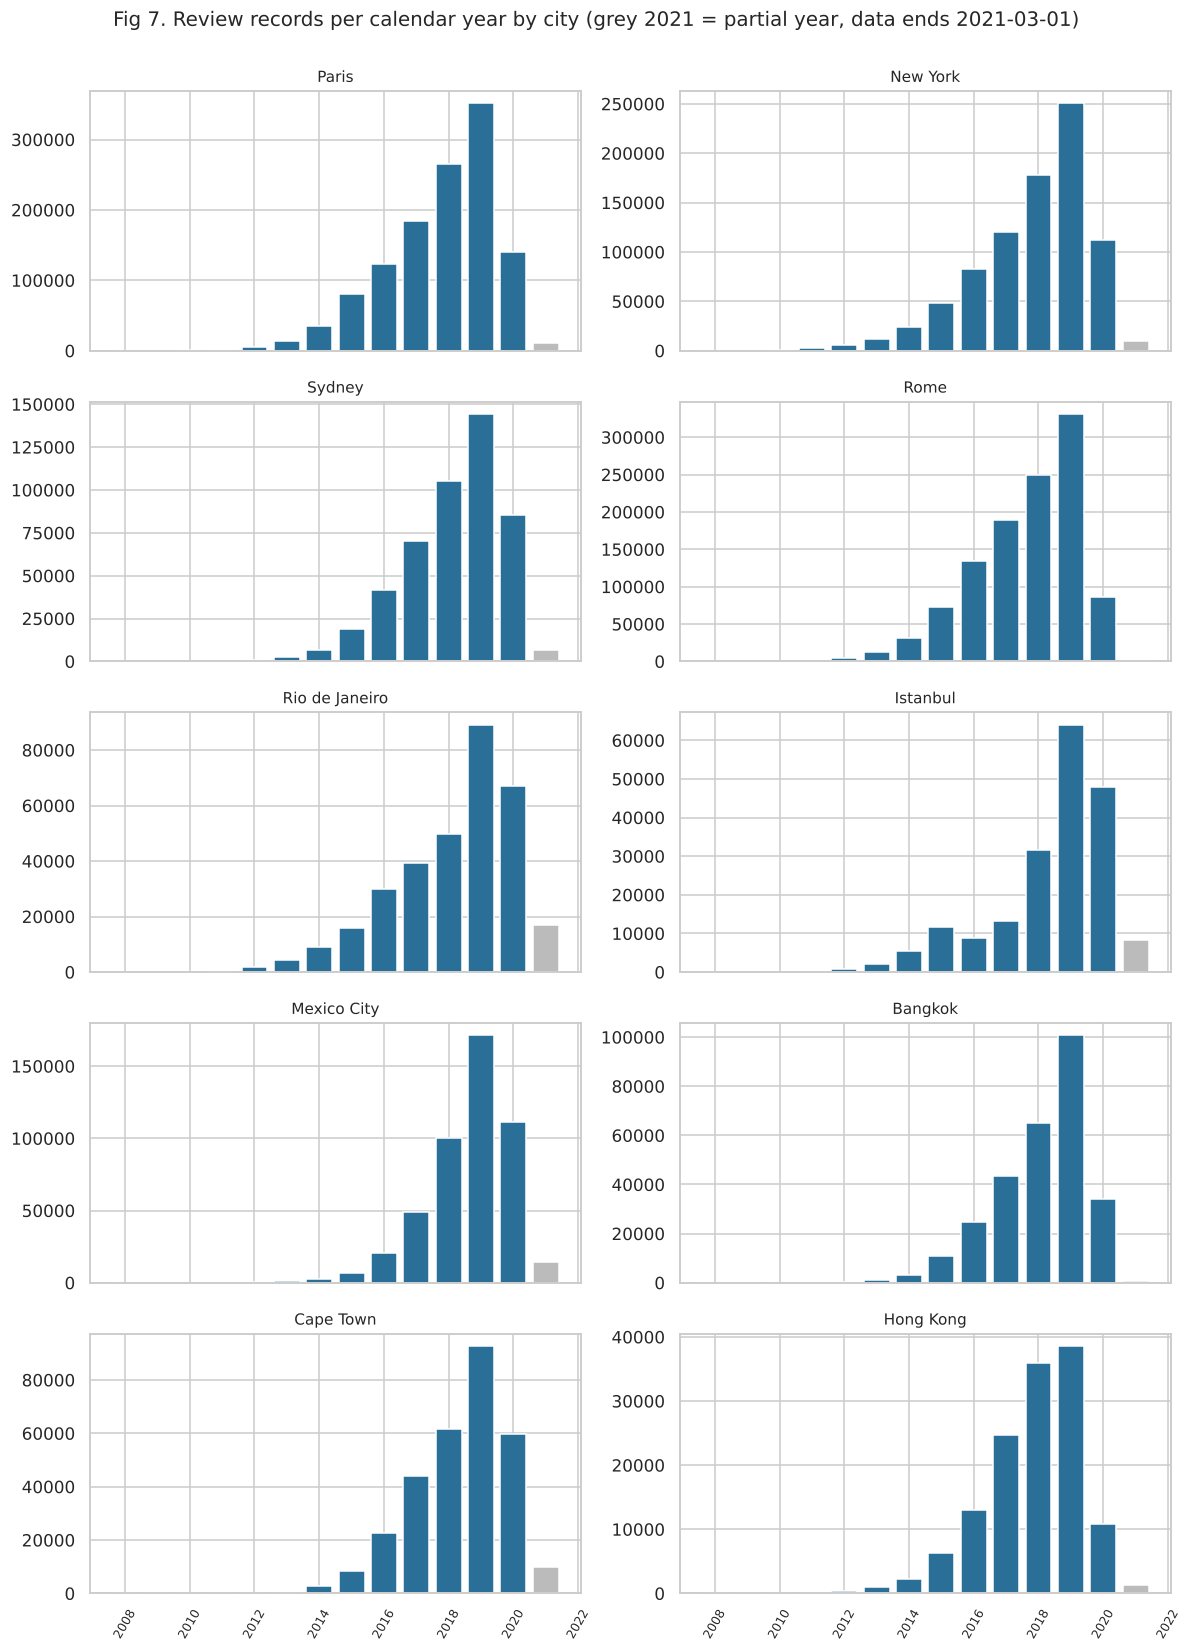

In [13]:
yr = con.sql('SELECT l.city, year(r.date) AS year, count(*) AS reviews FROM reviews r JOIN listings_min l USING(listing_id) GROUP BY 1,2 ORDER BY 1,2').df()
assert yr.reviews.sum() == dq['reviews_rows'], 'yearly totals must reconcile to the review file'
ypiv = yr.pivot(index='year', columns='city', values='reviews').fillna(0).astype(int)[order]; display(ypiv); ypiv.to_csv(TAB/'reviews_per_year_by_city.csv')
chg = ((ypiv.loc[2020]/ypiv.loc[2019]-1)*100).round(1).rename('2020 vs 2019 change %'); display(chg.to_frame().T)
RESULTS['reviews_2020_vs_2019_pct'] = chg.to_dict()

fig, axes = plt.subplots(5,2, figsize=(11,15), sharex=True)
for ax, c in zip(axes.ravel(), order):
    s = ypiv[c]; cols = ['#2a6f97' if y<2021 else '#bbbbbb' for y in s.index]
    ax.bar(s.index, s.values, color=cols); ax.set_title(c, fontsize=10); ax.tick_params(axis='x', rotation=60, labelsize=8)
plt.suptitle('Fig 7. Review records per calendar year by city (grey 2021 = partial year, data ends '+dq['date_max']+')', y=1.0, fontsize=13)
plt.tight_layout(); savefig('fig07_reviews_per_year.png')

In [14]:
def kruskal_eps(df, y, grp, min_n=MIN_N):
    sizes = df[grp].value_counts(); keep = sizes[sizes>=min_n].index; d = df[df[grp].isin(keep)]
    groups = [x[y].values for _,x in d.groupby(grp, observed=True)]
    if len(groups) < 2: return None
    H, p = stats.kruskal(*groups); n, k = len(d), len(groups)
    return dict(n=n, k_groups=k, H=H, p=p, epsilon2=(H-k+1)/(n-k))

rows, post = [], []
for c in order:
    g = A[A.city==c]; r = kruskal_eps(g, 'price', 'room_type'); r['city'] = c; r['currency'] = CURRENCY[c]
    gl = g.groupby('room_type').price.agg(['median','size']); r['median_by_room_type'] = '; '.join(f'{k}: {v:,.0f}' for k,v in gl[gl['size']>=MIN_N]['median'].items())
    rows.append(r)
    ref = g[g.room_type=='Entire place'].price.values
    for rt_ in gl[(gl['size']>=MIN_N)].index:
        if rt_=='Entire place': continue
        x = g[g.room_type==rt_].price.values; U,p = stats.mannwhitneyu(x, ref, alternative='two-sided')
        post.append(dict(city=c, room_type=rt_, n=len(x), median=np.median(x), median_entire=np.median(ref), CLES_vs_entire=U/(len(x)*len(ref)), p=p))
H1 = pd.DataFrame(rows).set_index('city'); H1['p_holm'] = multipletests(H1.p, method='holm')[1]
P1 = pd.DataFrame(post); P1['p_holm'] = multipletests(P1.p, method='holm')[1]
H1_show = H1[['currency','n','k_groups','H','epsilon2','p','p_holm','median_by_room_type']].copy()
H1_show['p'] = H1_show.p.map(fmt_p); H1_show['p_holm'] = H1_show.p_holm.map(fmt_p); display(H1_show.round(3))
P1_show = P1.copy(); P1_show['p_holm'] = P1_show.p_holm.map(fmt_p); P1_show = P1_show.drop(columns='p'); display(P1_show.round(3))
H1.to_csv(TAB/'H1_room_type_price_kruskal.csv'); P1.to_csv(TAB/'H1_posthoc_vs_entire_place.csv', index=False)
RESULTS['H1'] = H1[['n','epsilon2','p_holm']].to_dict('index')
print('Cities rejecting H0 after Holm:', int((H1.p_holm<ALPHA).sum()), 'of', len(H1), '| epsilon^2 range:', round(H1.epsilon2.min(),3), '-', round(H1.epsilon2.max(),3))

,currency,n,k_groups,H,epsilon2,p,p_holm,median_by_room_type
city,,,,,,,,
Paris,EUR,64628,4,5339.005,0.083,<1e-300,<1e-300,Entire place: 82; Hotel room: 162; Private roo...
New York,USD,36984,4,15303.152,0.414,<1e-300,<1e-300,Entire place: 140; Hotel room: 163; Private ro...
Sydney,AUD,33630,4,14359.647,0.427,<1e-300,<1e-300,Entire place: 176; Hotel room: 149; Private ro...
Rome,EUR,27641,4,4243.480,0.153,<1e-300,<1e-300,Entire place: 77; Hotel room: 60; Private room...
Rio de Janeiro,BRL,26608,4,4062.885,0.153,<1e-300,<1e-300,Entire place: 350; Hotel room: 194; Private ro...
Istanbul,TRY,24517,4,5308.340,0.216,<1e-300,<1e-300,Entire place: 350; Hotel room: 325; Private ro...
Mexico City,MXN,20058,4,6586.430,0.328,<1e-300,<1e-300,"Entire place: 950; Hotel room: 1,301; Private ..."
Bangkok,THB,19360,4,932.983,0.048,6.21e-202,6.21e-202,"Entire place: 1,192; Hotel room: 1,275; Privat..."
Cape Town,ZAR,19086,4,2689.313,0.141,<1e-300,<1e-300,"Entire place: 1,288; Hotel room: 1,350; Privat..."


,city,room_type,n,median,median_entire,CLES_vs_entire,p_holm
0,Paris,Hotel room,1334,162.5,82.0,0.786,1.71e-278
1,Paris,Private room,7492,53.0,82.0,0.293,<1e-300
2,Paris,Shared room,424,34.0,82.0,0.119,2.42e-160
3,New York,Hotel room,271,163.0,140.0,0.588,4.02e-06
4,New York,Private room,16630,60.0,140.0,0.129,<1e-300
5,New York,Shared room,686,45.0,140.0,0.124,3.09e-245
6,Sydney,Hotel room,233,149.0,176.0,0.418,8.42e-05
7,Sydney,Private room,12445,68.0,176.0,0.117,<1e-300
8,Sydney,Shared room,594,39.0,176.0,0.057,3.50e-296
9,Rome,Hotel room,1270,60.0,77.0,0.388,2.35e-39


Cities rejecting H0 after Holm: 10 of 10 | epsilon^2 range: 0.048 - 0.427


**H1 result.** H0 is rejected in all 10 cities (Holm-adjusted p < 0.05). The *size* of the room-type effect varies widely: ε² ranges from 0.048 (Bangkok) and 0.083 (Paris) up to 0.414 (New York) and 0.427 (Sydney). In every city private rooms and shared rooms are priced below entire places (CLES vs entire place 0.12–0.46 for private rooms, 0.06–0.18 for shared rooms). Hotel rooms are *not* uniformly a premium: they are priced higher than entire places in Paris (CLES 0.79), New York (0.59) and Mexico City (0.57), lower in Sydney, Rome, Rio de Janeiro and Hong Kong, and essentially at parity in Bangkok (0.53), Istanbul (0.47) and Cape Town (no significant difference, Holm p = 0.40). **Statistical vs practical significance:** all p-values are tiny because n is large; in Bangkok and Paris room type explains little of the price ordering, while in New York and Sydney it explains a large share.

In [15]:
def spearman(x, y):
    m = x.notna() & y.notna(); x, y = x[m], y[m]; n = len(x)
    rho, p = stats.spearmanr(x, y); se = np.sqrt((1+rho**2/2)/(n-3)); z = np.arctanh(rho)
    return dict(n=n, rho=rho, ci_low=np.tanh(z-1.96*se), ci_high=np.tanh(z+1.96*se), p=p)

def spearman_by_city(df, xcol, ycol):
    out = []
    for c in order:
        g = df[df.city==c]; r = spearman(g[xcol], g[ycol]); r['city'] = c; out.append(r)
    t = pd.DataFrame(out).set_index('city'); t['p_holm'] = multipletests(t.p, method='holm')[1]; return t

H2a = spearman_by_city(A, 'accommodates', 'price')
H2b = spearman_by_city(A[A.room_type=='Entire place'], 'bedrooms', 'price')
H2c = spearman_by_city(A, 'bedrooms', 'price')
for name, t in [('H2a: price ~ accommodates (all room types)', H2a), ('H2b: price ~ bedrooms (Entire place only)', H2b), ('H2c: price ~ bedrooms (all room types)', H2c)]:
    print(name); s = t.copy(); s['p'] = s.p.map(fmt_p); s['p_holm'] = s.p_holm.map(fmt_p); display(s.round(3))
H2a.to_csv(TAB/'H2a_accommodates_price_spearman.csv'); H2b.to_csv(TAB/'H2b_bedrooms_entire_price_spearman.csv'); H2c.to_csv(TAB/'H2c_bedrooms_all_price_spearman.csv')
RESULTS['H2a'] = H2a[['n','rho','ci_low','ci_high','p_holm']].to_dict('index'); RESULTS['H2b'] = H2b[['n','rho','ci_low','ci_high','p_holm']].to_dict('index')

H2a: price ~ accommodates (all room types)


,n,rho,ci_low,ci_high,p,p_holm
city,,,,,,
Paris,64628,0.529,0.523,0.535,<1e-300,<1e-300
New York,36984,0.554,0.546,0.561,<1e-300,<1e-300
Sydney,33630,0.680,0.674,0.686,<1e-300,<1e-300
Rome,27641,0.494,0.485,0.503,<1e-300,<1e-300
Rio de Janeiro,26608,0.518,0.508,0.527,<1e-300,<1e-300
Istanbul,24517,0.506,0.496,0.516,<1e-300,<1e-300
Mexico City,20058,0.557,0.546,0.567,<1e-300,<1e-300
Bangkok,19360,0.313,0.300,0.326,<1e-300,<1e-300
Cape Town,19086,0.671,0.662,0.679,<1e-300,<1e-300


H2b: price ~ bedrooms (Entire place only)


,n,rho,ci_low,ci_high,p,p_holm
city,,,,,,
Paris,42346,0.512,0.505,0.520,<1e-300,<1e-300
New York,16294,0.342,0.328,0.356,<1e-300,<1e-300
Sydney,18784,0.629,0.619,0.638,<1e-300,<1e-300
Rome,16557,0.429,0.416,0.442,<1e-300,<1e-300
Rio de Janeiro,17733,0.568,0.557,0.579,<1e-300,<1e-300
Istanbul,11349,0.410,0.394,0.425,<1e-300,<1e-300
Mexico City,10162,0.388,0.371,0.405,<1e-300,<1e-300
Bangkok,9411,0.530,0.515,0.546,<1e-300,<1e-300
Cape Town,12985,0.729,0.720,0.738,<1e-300,<1e-300


H2c: price ~ bedrooms (all room types)


,n,rho,ci_low,ci_high,p,p_holm
city,,,,,,
Paris,51286,0.485,0.478,0.492,<1e-300,<1e-300
New York,33404,0.455,0.446,0.464,<1e-300,<1e-300
Sydney,31421,0.651,0.644,0.658,<1e-300,<1e-300
Rome,26773,0.437,0.427,0.447,<1e-300,<1e-300
Rio de Janeiro,24869,0.570,0.560,0.579,<1e-300,<1e-300
Istanbul,22485,0.372,0.360,0.383,<1e-300,<1e-300
Mexico City,19256,0.467,0.455,0.479,<1e-300,<1e-300
Bangkok,17219,0.431,0.418,0.443,<1e-300,<1e-300
Cape Town,17707,0.669,0.660,0.678,<1e-300,<1e-300


**H2 result.** H0 is rejected in every city for every variant (Holm p < 0.05). Capacity is positively and moderately-to-strongly associated with price: ρ = 0.31 (Bangkok) to 0.68 (Sydney); the other cities lie between 0.49 and 0.67. Among entire places, bedrooms show ρ = 0.34 (New York) to 0.73 (Cape Town). The confidence intervals are narrow (typically ±0.01–0.02), so differences between cities (e.g. Bangkok vs Sydney) are real *in this data*. These are **associations**: larger listings are priced higher, but the data cannot say that adding a bedroom raises price. Capacity and bedrooms are themselves correlated, so §5 estimates their joint contribution.

In [16]:
E = A[A.room_type=='Entire place']
rows, nb_rows = [], []
for c in order:
    g = E[E.city==c]; r = kruskal_eps(g, 'price', 'neighbourhood'); r['city'] = c
    s = g.groupby('neighbourhood').price.agg(['median','size']); s = s[s['size']>=MIN_N].sort_values('median')
    r['cheapest_neighbourhood'] = f"{s.index[0]} ({s['median'].iloc[0]:,.0f})"; r['dearest_neighbourhood'] = f"{s.index[-1]} ({s['median'].iloc[-1]:,.0f})"
    r['dearest_to_cheapest_median_ratio'] = s['median'].iloc[-1]/s['median'].iloc[0]; rows.append(r)
H3 = pd.DataFrame(rows).set_index('city'); H3['p_holm'] = multipletests(H3.p, method='holm')[1]
s3 = H3[['n','k_groups','epsilon2','p','p_holm','cheapest_neighbourhood','dearest_neighbourhood','dearest_to_cheapest_median_ratio']].copy()
s3['p'] = s3.p.map(fmt_p); s3['p_holm'] = s3.p_holm.map(fmt_p); display(s3.round(3)); H3.to_csv(TAB/'H3_neighbourhood_price_kruskal.csv')
RESULTS['H3'] = H3[['n','k_groups','epsilon2','p_holm']].to_dict('index')

,n,k_groups,epsilon2,p,p_holm,cheapest_neighbourhood,dearest_neighbourhood,dearest_to_cheapest_median_ratio
city,,,,,,,,
Paris,55378,20,0.103,<1e-300,<1e-300,Menilmontant (67),Elysee (120),1.791
New York,18280,78,0.115,<1e-300,<1e-300,Midwood (87),Tribeca (256),2.943
Sydney,20335,37,0.134,<1e-300,<1e-300,Fairfield (100),Pittwater (445),4.450
Rome,17248,15,0.102,<1e-300,<1e-300,V Prenestino/Centocelle (49),I Centro Storico (89),1.816
Rio de Janeiro,18641,39,0.119,<1e-300,<1e-300,Centro (150),"Joa (3,500)",23.333
Istanbul,12296,31,0.058,5.45e-137,1.09e-136,Pendik (258),Silivri (990),3.830
Mexico City,10518,14,0.103,1.69e-225,5.08e-225,Iztapalapa (456),"Miguel Hidalgo (1,225)",2.686
Bangkok,10397,37,0.122,1.96e-249,7.84e-249,Wang Thong Lang (644),"Parthum Wan (2,101)",3.262
Cape Town,13895,37,0.155,<1e-300,<1e-300,Ward 2 (598),"Ward 62 (3,000)",5.021


**H3 result.** H0 is rejected in all 10 cities: even among entire places only, neighbourhood is associated with price (ε² from 0.054 in Hong Kong to 0.155 in Cape Town — a small-to-medium effect). The ratio between the most and least expensive neighbourhood (each with ≥ 30 listings) ranges from about 1.8× (Paris, Rome) to 23.3× (Rio de Janeiro: Joa vs Centro). The ratio of two extreme groups is sensitive to composition (which listings happen to be in each area) and should be read as descriptive. Neighbourhood labels are ASCII-folded in the source (e.g. accents missing) and 977 cells contain corrupted bytes; labels were used as supplied.

In [17]:
H4 = spearman_by_city(R, 'review_count', 'review_scores_rating')
pooled = spearman(R.review_count, R.review_scores_rating); pooled['city'] = 'ALL CITIES (pooled)'; pooled['p_holm'] = pooled['p']
H4p = pd.concat([H4, pd.DataFrame([pooled]).set_index('city')]); s = H4p.copy(); s['p'] = s.p.map(fmt_p); s['p_holm'] = s.p_holm.map(fmt_p); display(s.round(3))
H4p.to_csv(TAB/'H4_reviewcount_rating_spearman.csv'); RESULTS['H4'] = H4p[['n','rho','ci_low','ci_high','p_holm']].to_dict('index')
# Does the *spread* of ratings shrink with more reviews? (variance / small-sample noise explanation)
print('Std-dev of rating by review-volume bucket:'); display(R.groupby('rc_bin', observed=True).review_scores_rating.std().round(2).to_frame('std').T)

,n,rho,ci_low,ci_high,p,p_holm
city,,,,,,
Paris,48036,-0.181,-0.190,-0.172,<1e-300,<1e-300
New York,26777,-0.228,-0.240,-0.217,<1e-300,<1e-300
Sydney,22376,-0.208,-0.221,-0.195,1.77e-217,1.24e-216
Rome,20892,-0.128,-0.141,-0.114,1.25e-76,2.49e-76
Rio de Janeiro,16118,-0.279,-0.294,-0.264,4.23e-286,3.39e-285
Istanbul,11229,-0.193,-0.211,-0.175,2.40e-94,7.19e-94
Mexico City,14484,-0.253,-0.268,-0.237,7.53e-210,4.52e-209
Bangkok,11181,-0.201,-0.219,-0.183,1.39e-102,5.56e-102
Cape Town,13435,-0.199,-0.215,-0.182,9.22e-120,4.61e-119


Std-dev of rating by review-volume bucket:


rc_bin,1,2,3-5,6-10,11-25,26-50,51-100,100+
std,19.06,13.39,9.67,6.9,4.97,4.19,3.82,3.63


**H4 result.** The association is **negative** in every city (ρ from −0.03 in Hong Kong to −0.28 in Rio de Janeiro; pooled ρ = −0.205, 95% CI −0.209 to −0.201). Hong Kong is borderline and negligible (Holm p = 0.046). The bucket table in §3.5 shows why: 73% of listings with a single review have a perfect 100 rating, falling to 1.5% of listings with 100+ reviews, while the spread of ratings narrows steadily with volume. This pattern is what small-sample noise plus a ceiling at 100 would produce — a listing with one review can only be 100 or lower — so it should **not** be read as "popular listings are worse". The data cannot separate that explanation from genuine quality differences, and review *records* are not bookings or satisfaction.

In [18]:
rows = []
for c in order:
    g = R[R.city==c]; r = kruskal_eps(g, 'review_scores_rating', 'room_type'); r['city'] = c
    gl = g.groupby('room_type').review_scores_rating.agg(['median','mean','size']); r['mean_rating_by_room_type'] = '; '.join(f'{k}: {v:.1f}' for k,v in gl[gl['size']>=MIN_N]['mean'].items()); rows.append(r)
rp = kruskal_eps(R, 'review_scores_rating', 'room_type'); rp['city'] = 'ALL CITIES (pooled)'
gl = R.groupby('room_type').review_scores_rating.agg(['mean','size']); rp['mean_rating_by_room_type'] = '; '.join(f'{k}: {v:.1f}' for k,v in gl[gl['size']>=MIN_N]['mean'].items()); rows.append(rp)
H5 = pd.DataFrame(rows).set_index('city'); H5['p_holm'] = np.r_[multipletests(H5.p.iloc[:-1], method='holm')[1], H5.p.iloc[-1]]
s = H5[['n','k_groups','epsilon2','p','p_holm','mean_rating_by_room_type']].copy(); s['p'] = s.p.map(fmt_p); s['p_holm'] = s.p_holm.map(fmt_p); display(s.round(3))
H5.to_csv(TAB/'H5_room_type_rating_kruskal.csv'); RESULTS['H5'] = H5[['n','epsilon2','p_holm']].to_dict('index')

,n,k_groups,epsilon2,p,p_holm,mean_rating_by_room_type
city,,,,,,
Paris,48036,4,0.001,7.36e-16,3.68e-15,Entire place: 93.0; Hotel room: 91.7; Private ...
New York,26777,4,0.006,2.74e-37,2.74e-36,Entire place: 94.5; Hotel room: 88.5; Private ...
Sydney,22376,4,0.003,4.64e-14,1.39e-13,Entire place: 93.8; Hotel room: 90.6; Private ...
Rome,20892,4,0.003,2.28e-14,9.11e-14,Entire place: 94.1; Hotel room: 90.8; Private ...
Rio de Janeiro,16118,4,0.009,6.29e-33,5.03e-32,Entire place: 94.5; Hotel room: 94.2; Private ...
Istanbul,11229,4,0.014,8.38e-35,7.54e-34,Entire place: 91.4; Hotel room: 87.3; Private ...
Mexico City,14484,4,0.006,8.25e-20,5.78e-19,Entire place: 95.2; Hotel room: 93.1; Private ...
Bangkok,11181,4,0.002,6.01e-05,1.20e-04,Entire place: 93.6; Hotel room: 91.5; Private ...
Cape Town,13435,4,0.001,0.0018,0.0018,Entire place: 94.8; Hotel room: 91.3; Private ...


**H5 result.** H0 is rejected in all cities and pooled, but the effects are trivial: ε² ≤ 0.023 in every city and 0.002 pooled. Hotel-room listings have the lowest or near-lowest mean rating in most cities (largest gap in New York: 88.5 vs 94.5 for entire places), but room type explains at most about 2% of the rank variation in ratings. With ratings piled up near the ceiling, room type is not a useful discriminator of listing-level ratings in this data.

In [19]:
ols_rows = []
for c in order:
    g = A[(A.city==c) & A.accommodates.notna() & A.bedrooms.notna()].copy()
    vc = g.neighbourhood.value_counts(); g['nb'] = np.where(g.neighbourhood.isin(vc[vc>=MIN_N].index), g.neighbourhood, 'Other')
    f = {'room type':'log_price ~ C(room_type)', '+ capacity':'log_price ~ C(room_type)+accommodates', '+ bedrooms':'log_price ~ C(room_type)+accommodates+bedrooms',
         '+ neighbourhood':'log_price ~ C(room_type)+accommodates+bedrooms+C(nb)'}
    row = {'city':c, 'n':len(g)}
    for k,v in f.items(): row[k] = smf.ols(v, data=g).fit().rsquared_adj
    ols_rows.append(row)
OLS = pd.DataFrame(ols_rows).set_index('city'); display(OLS.round(3)); OLS.to_csv(TAB/'supplementary_nested_ols_adjR2.csv')
RESULTS['OLS_adjR2'] = OLS.to_dict('index')

,n,room type,+ capacity,+ bedrooms,+ neighbourhood
city,,,,,
Paris,51286,0.116,0.347,0.354,0.441
New York,33404,0.368,0.441,0.448,0.554
Sydney,31421,0.375,0.551,0.572,0.614
Rome,26773,0.130,0.260,0.273,0.328
Rio de Janeiro,24869,0.149,0.280,0.334,0.376
Istanbul,22485,0.182,0.269,0.269,0.297
Mexico City,19256,0.260,0.341,0.343,0.387
Bangkok,17219,0.044,0.176,0.188,0.230
Cape Town,17707,0.145,0.481,0.483,0.573


**Reading the nested models.** Room type alone explains 4% (Bangkok) to 38% (Sydney) of the variance in log price. Adding capacity gives the largest gain in most cities (Paris 0.12 → 0.35; Cape Town 0.15 → 0.48); bedrooms add little once capacity is in; neighbourhood adds a further 0.03–0.11. The full set reaches adjusted R² of 0.23 (Bangkok) to 0.61 (Sydney), so **39–77% of price variation is left unexplained** by the attributes tested — quality, amenities, view, season and host pricing strategy are not captured. This sets a realistic ceiling for what a price model built only on these fields can achieve (relevant to Track C).

In [20]:
A2 = A[~A.price_extreme]
r1 = pd.DataFrame({c: kruskal_eps(A2[A2.city==c], 'price', 'room_type') for c in order}).T[['n','epsilon2']].astype(float)
r2 = spearman_by_city(A2, 'accommodates', 'price')[['n','rho']]
rob = pd.DataFrame({'H1 eps2 (all)':H1.epsilon2, 'H1 eps2 (no extremes)':r1.epsilon2, 'H2a rho (all)':H2a.rho, 'H2a rho (no extremes)':r2.rho, 'n removed':A.groupby('city').price_extreme.sum()})
display(rob.round(3)); rob.to_csv(TAB/'robustness_excluding_extremes.csv'); RESULTS['robustness'] = rob.to_dict('index')
print('max |change| in H1 eps2:', round((rob['H1 eps2 (all)']-rob['H1 eps2 (no extremes)']).abs().max(),3), '| max |change| in H2a rho:', round((rob['H2a rho (all)']-rob['H2a rho (no extremes)']).abs().max(),3))

,H1 eps2 (all),H1 eps2 (no extremes),H2a rho (all),H2a rho (no extremes),n removed
Bangkok,0.048,0.049,0.313,0.313,80
Cape Town,0.141,0.141,0.671,0.670,22
Hong Kong,0.266,0.269,0.513,0.513,12
Istanbul,0.216,0.218,0.506,0.507,53
Mexico City,0.328,0.329,0.557,0.557,37
New York,0.414,0.415,0.554,0.554,62
Paris,0.083,0.083,0.529,0.529,192
Rio de Janeiro,0.153,0.154,0.518,0.518,51
Rome,0.153,0.156,0.494,0.495,104
Sydney,0.427,0.429,0.680,0.681,28


max |change| in H1 eps2: 0.002 | max |change| in H2a rho: 0.001


**Robustness.** Removing the 641 extreme-price listings changes ε² by at most 0.003 and ρ by at most 0.001, so none of the conclusions depend on the extreme values (expected, since the tests are rank-based).

,H1 room type -> price (eps2),H2a capacity ~ price (rho),"H2b bedrooms ~ price, entire places (rho)","H3 neighbourhood -> price, entire places (eps2)",H4 review count ~ rating (rho),H5 room type -> rating (eps2)
city,,,,,,
Paris,0.083,0.529,0.512,0.103,-0.181,0.001
New York,0.414,0.554,0.342,0.115,-0.228,0.006
Sydney,0.427,0.680,0.629,0.134,-0.208,0.003
Rome,0.153,0.494,0.429,0.102,-0.128,0.003
Rio de Janeiro,0.153,0.518,0.568,0.119,-0.279,0.009
Istanbul,0.216,0.506,0.410,0.058,-0.193,0.014
Mexico City,0.328,0.557,0.388,0.103,-0.253,0.006
Bangkok,0.048,0.313,0.530,0.122,-0.201,0.002
Cape Town,0.141,0.671,0.729,0.155,-0.199,0.001


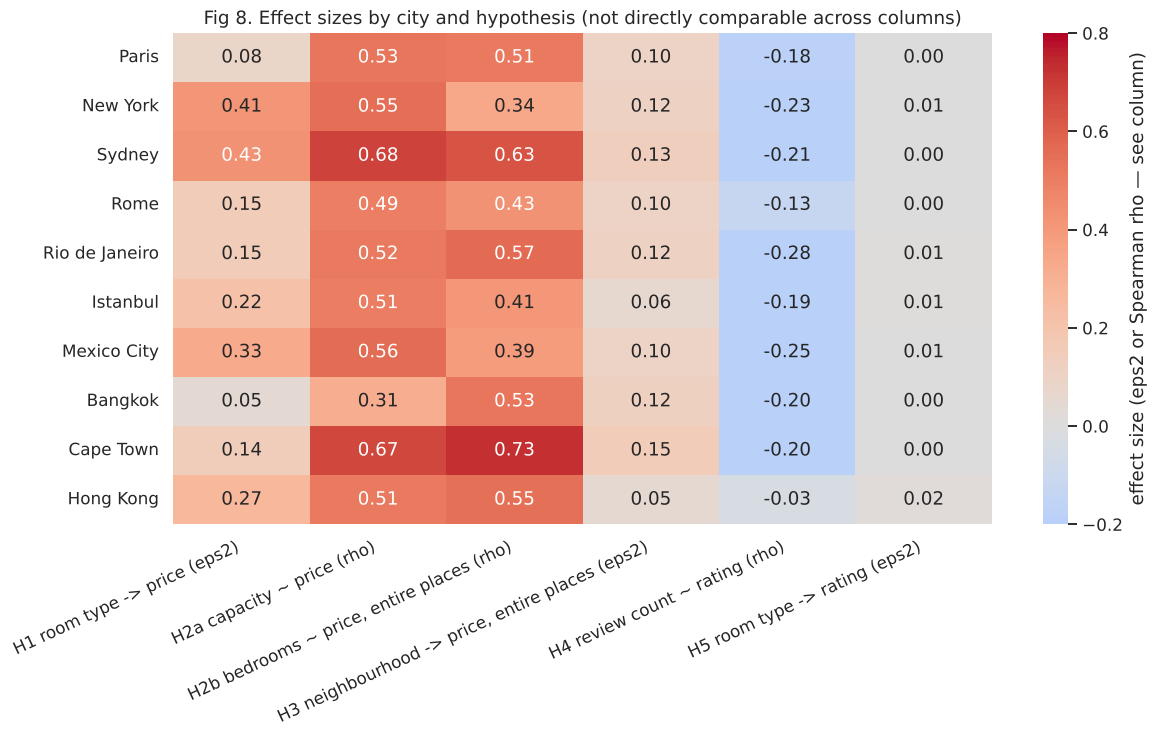

In [21]:
summ = pd.DataFrame({'H1 room type -> price (eps2)':H1.epsilon2, 'H2a capacity ~ price (rho)':H2a.rho, 'H2b bedrooms ~ price, entire places (rho)':H2b.rho,
                     'H3 neighbourhood -> price, entire places (eps2)':H3.epsilon2, 'H4 review count ~ rating (rho)':H4.rho, 'H5 room type -> rating (eps2)':H5.epsilon2.iloc[:-1]}).loc[order]
display(summ.round(3)); summ.to_csv(TAB/'effect_size_summary.csv')
fig, ax = plt.subplots(figsize=(12,5.8))
sns.heatmap(summ, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-.2, vmax=.8, cbar_kws={'label':'effect size (eps2 or Spearman rho — see column)'}, ax=ax)
ax.set_title('Fig 8. Effect sizes by city and hypothesis (not directly comparable across columns)'); ax.set_ylabel(''); plt.xticks(rotation=25, ha='right')
savefig('fig08_effect_size_summary.png')

## 8. Independent validation of key figures (DuckDB straight from the CSV vs pandas)

In [22]:
v = duckdb.connect()
try: v.execute("SET enable_progress_bar=false")
except Exception: pass
# DuckDB rejects the file's mixed encoding, so give it a byte-sanitised temp copy (same rows; only invalid bytes replaced)
tmp = OUT/'_listings_sanitised.csv'
tmp.write_text((DATA_DIR/'Listings.csv').read_bytes().decode('utf-8', errors='replace'), encoding='utf-8')
sql = v.execute(f"SELECT city, count(*) n, median(price) med FROM read_csv('{tmp.as_posix()}', header=true) WHERE price>0 GROUP BY 1 ORDER BY 1").df().set_index('city')
tmp.unlink()
chk = pd.DataFrame({'sql_n':sql.n, 'pandas_n':A.groupby('city').size(), 'sql_median':sql.med, 'pandas_median':A.groupby('city').price.median()})
chk['match'] = (chk.sql_n==chk.pandas_n) & (np.isclose(chk.sql_median, chk.pandas_median)); display(chk)
assert chk.match.all(), 'validation mismatch'
assert L.city.value_counts().sum() == dq['listings_rows'] == 279712
assert dq['reviews_rows'] == 5373143 and ypiv.values.sum() == 5373143
assert len(A) == dq['listings_rows'] - dq['price_nonpositive']
# Spearman cross-check with an independent implementation (rank -> Pearson) for one city
g = A[(A.city=='Paris') & A.accommodates.notna()]; alt = np.corrcoef(g.accommodates.rank(), g.price.rank())[0,1]
assert abs(alt - H2a.loc['Paris','rho']) < 1e-9; print('Spearman Paris cross-check OK:', round(alt,4))
# Kruskal-Wallis cross-check: H recomputed from ranks (tie-corrected) for one city
g = A[A.city=='Rome']; g = g[g.room_type.isin(H1.index[0:0].tolist() or g.room_type.value_counts()[lambda s:s>=MIN_N].index)]
rk = g.price.rank(); n = len(g); Hm = 12/(n*(n+1))*sum(len(x)*(x.mean()-(n+1)/2)**2 for _,x in rk.groupby(g.room_type))
ties = g.price.value_counts(); Hm /= (1 - (ties**3-ties).sum()/(n**3-n))
assert abs(Hm - H1.loc['Rome','H']) < 1e-6; print('Kruskal-Wallis Rome cross-check OK:', round(Hm,2))
print('All validation checks passed.')

,sql_n,pandas_n,sql_median,pandas_median,match
city,,,,,
Bangkok,19360,19360,1100.0,1100.0,True
Cape Town,19086,19086,1069.0,1069.0,True
Hong Kong,7087,7087,386.0,386.0,True
Istanbul,24517,24517,252.0,252.0,True
Mexico City,20058,20058,664.0,664.0,True
New York,36984,36984,99.0,99.0,True
Paris,64628,64628,80.0,80.0,True
Rio de Janeiro,26608,26608,280.0,280.0,True
Rome,27641,27641,65.0,65.0,True


Spearman Paris cross-check OK: 0.5294
Kruskal-Wallis Rome cross-check OK: 4243.48
All validation checks passed.


In [23]:
d = dq; ds = d['dup_summary']
txt = f"""# Data-Quality Summary — Airbnb Listings & Reviews

*Generated by the notebook; every number below is computed from the supplied files.*

## Files
| File | Rows | Columns |
|---|---|---|
| Listings.csv | {d['listings_rows']:,} | {d['listings_cols']} |
| Reviews.csv | {d['reviews_rows']:,} | 4 |
| Listings_data_dictionary.csv / Reviews_data_dictionary.csv | 33 / 4 field definitions | 2 |

## Keys and relationships
- `listing_id` (Listings): unique = **{d['listing_id_unique']}**, nulls = {d['listing_id_nulls']}, full-row duplicates = {d['listings_full_row_duplicates']}.
- Reviews: {d['reviews_distinct_review_id']:,} distinct `review_id` over {d['reviews_rows']:,} rows -> **{d['duplicated_review_ids']} duplicated review_id values**. `(listing_id, review_id)` distinct pairs = {d['reviews_distinct_pairs']:,} (unique).
- Foreign key: orphan review rows (listing_id not in Listings) = **{d['orphan_reviews']}**. Relationship is one-to-many.
- Listings with >=1 review row: {d['listings_with_reviews']:,}; with none: {d['listings_without_reviews']:,}.
- Review dates: {d['date_min']} to {d['date_max']} (no null cells in Reviews).

## Duplicate review_id investigation
Every duplicated id appears exactly twice; always on two different listings (different hosts, same city) with the same reviewer and same date. Treatment: **retained** (rows affected = {ds['rows involved']}, {ds['share of all review rows']} of the file); review counts use (listing_id, review_id).

## Missing values (Listings)
| Column | Missing | % |
|---|---|---|
""" + '\n'.join(f"| {k} | {int(v['missing']):,} | {v['pct']} |" for k,v in d['missing'].items()) + f"""

Treatment: no imputation; complete-case analysis per test. `district` exists only for New York. Missing ratings coincide with no review rows ({d['crosstab_reviews_vs_rating']['no_reviews_no_rating']:,} listings have neither; {d['crosstab_reviews_vs_rating']['reviews_no_rating']:,} have reviews but no rating; {d['crosstab_reviews_vs_rating']['no_reviews_rating']} has a rating but no review rows).

## Price and currency
- `price` dtype: {d['price_dtype']}. Non-positive prices: **{d['price_nonpositive']}** (excluded from analysis table). Analysis rows: {d['analysis_rows']:,}.
- No currency field; local currency inferred from city (assumption). Prices are never pooled across cities.
- Extreme prices (3xIQR fence on within-city log10 price) flagged: {d['extreme_flagged']:,} - kept; robustness check in notebook section 6.
- Capacity (`accommodates`) = 0 set to missing for 85 listings.

## Text encoding
Listings.csv is not valid UTF-8. Cells containing a replacement character after a tolerant read: name {d['replacement_char_cells']['name']}, host_location {d['replacement_char_cells']['host_location']}, neighbourhood {d['replacement_char_cells']['neighbourhood']}. `name` has {d['mojibake_name_cells']:,} cells with double-encoding artefacts. `name` is not analysed; corrupted neighbourhood labels are retained as separate labels.
"""
(OUT/'data_quality_summary.md').write_text(txt, encoding='utf-8')
json.dump({'dq':dq, 'results':RESULTS}, open(OUT/'key_results.json','w'), indent=1, default=lambda o: o.item() if hasattr(o,'item') else str(o))
print(txt[:1500])

# Data-Quality Summary — Airbnb Listings & Reviews

*Generated by the notebook; every number below is computed from the supplied files.*

## Files
| File | Rows | Columns |
|---|---|---|
| Listings.csv | 279,712 | 33 |
| Reviews.csv | 5,373,143 | 4 |
| Listings_data_dictionary.csv / Reviews_data_dictionary.csv | 33 / 4 field definitions | 2 |

## Keys and relationships
- `listing_id` (Listings): unique = **True**, nulls = 0, full-row duplicates = 0.
- Reviews: 5,372,983 distinct `review_id` over 5,373,143 rows -> **160 duplicated review_id values**. `(listing_id, review_id)` distinct pairs = 5,373,143 (unique).
- Foreign key: orphan review rows (listing_id not in Listings) = **0**. Relationship is one-to-many.
- Listings with >=1 review row: 193,556; with none: 86,156.
- Review dates: 2008-11-16 to 2021-03-01 (no null cells in Reviews).

## Duplicate review_id investigation
Every duplicated id appears exactly twice; always on two different listings (different hosts, same city) with the